# Hydrological Data

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,DateTime
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-12-02
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,1946-01-02
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-30
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-03-02
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-04-01


<Axes: xlabel='x', ylabel='y'>

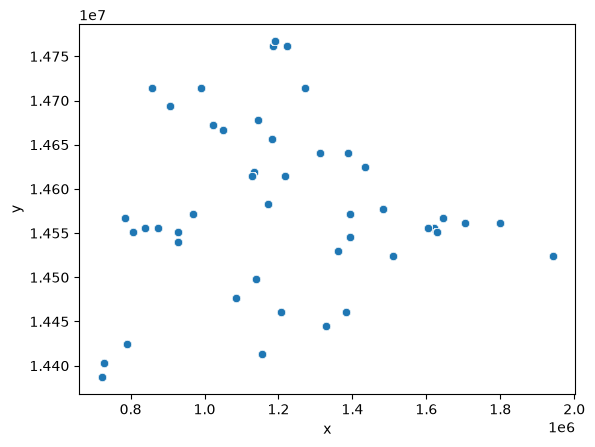

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data/RRCA_baseflow.csv')
# Date is days since 1/1/0000
df['DateTime'] = pd.to_datetime(df['Date'], unit='D', origin='0000-1-1')

display(df.head(5))

segments = df.copy()
segments.drop_duplicates(subset=['Segment_id'], keep='first')
segments

sns.scatterplot(data=segments, x='x', y='y')

Presumably the correlations will be a bit different for each segment. I wonder how/if you can account for that. Do we just have to leave out segment? Maybe there's a consistent relationship as x or y increases by I kinda doubt it.

It seems like the river branches out as you go left (idk whether it's a delta or those are tributaries). Either way `x` could be a meaningful feature. I doubt `y` would have any significant correlation.

min 1939-10-02 00:00:00 max 2000-09-01 00:00:00
Number of segments: 42


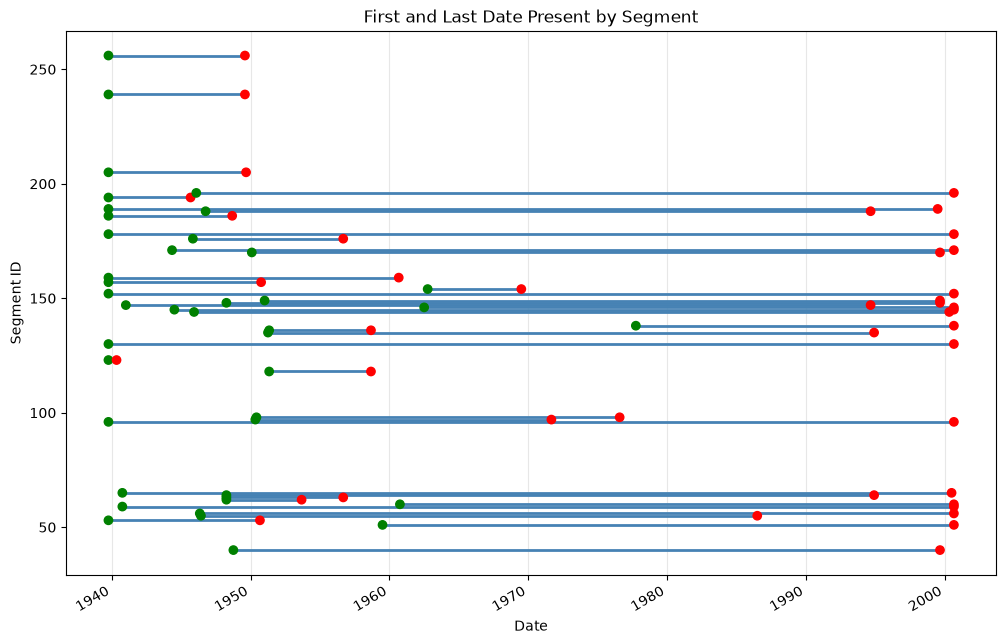

In [39]:
# Date range
print(f'min {df['DateTime'].min()} max {df['DateTime'].max()}')

# Research events during time range
num_segments = df['Segment_id'].nunique()
print(f'Number of segments: {num_segments}')
df['Segment_id'].value_counts(normalize=True)
# df[df['Segment_id'] == 123]
date_ranges = (
    df.groupby('Segment_id')['DateTime']
      .agg(first='min', last='max')
      .sort_values('first')
)

fig, ax = plt.subplots(figsize=(12, 8))

for segment_id, row in date_ranges.iterrows():
    ax.plot([row['first'], row['last']], [segment_id, segment_id],
            color='steelblue', linewidth=2)
    ax.scatter([row['first'], row['last']], [segment_id, segment_id],
               color=['green', 'red'], zorder=3)

ax.set_xlabel('Date')
ax.set_ylabel('Segment ID')
ax.set_title('First and Last Date Present by Segment')
ax.grid(axis='x', alpha=0.3)
fig.autofmt_xdate()
plt.show()

In [42]:
location_summary = (
    multi_location.groupby(["Segment_id", "x", "y"], dropna=False)
    .agg(
        first_reading=("DateTime", "min"),
        last_reading=("DateTime", "max"),
        row_count=("Segment_id", "size"),
    )
    .reset_index()
)

location_summary = (
    location_summary
    .merge(
        location_counts,
        on=["Segment_id", "x", "y"],
        how="left",
    )
    .sort_values(["Segment_id", "x", "y"])
)

display(location_summary)


,Segment_id,x,y,first_reading,last_reading,row_count,location_row_count
0,53,991150,14714400,1940-10-02,1950-09-01,120,120
1,53,1049230,14666880,1939-10-02,1949-09-01,120,120
2,152,1360750,14529600,1995-10-02,2000-09-01,60,60
3,152,1392430,14545440,1939-10-02,1972-09-01,396,396
4,159,1181230,14656320,1940-10-02,1948-03-02,90,90
5,159,1218190,14614080,1939-10-02,1960-09-01,252,252
6,171,1381870,14460960,1944-05-02,1964-10-02,246,246
7,171,1508590,14524320,1945-05-02,2000-09-01,447,447


Where/When is this?
Dates: 10/2/1939 - 9/1/2000

Republican River Basin - a 15.9-million-acre watershed spanning northeastern Colorado, southwestern Nebraska, and northwestern Kansas

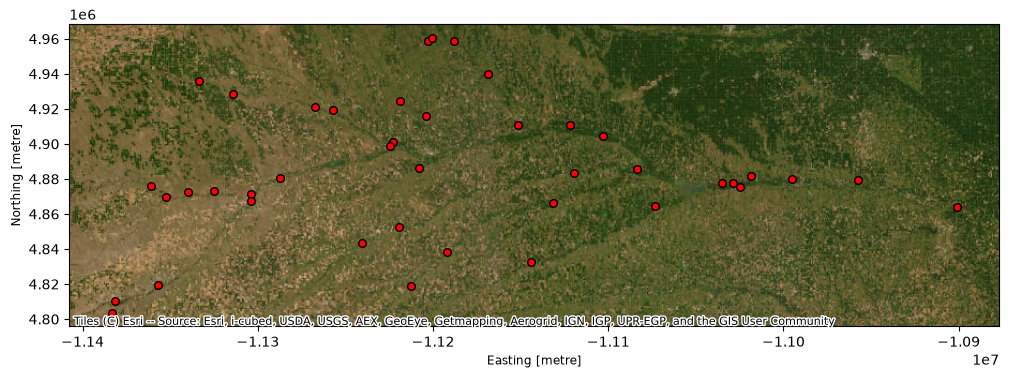

dict_keys(['WorldStreetMap', 'WorldTopoMap', 'WorldImagery', 'WorldTerrain', 'WorldShadedRelief', 'WorldPhysical', 'OceanBasemap', 'NatGeoWorldMap', 'WorldGrayCanvas', 'ArcticImagery', 'ArcticOceanBase', 'ArcticOceanReference', 'AntarcticImagery', 'AntarcticBasemap'])


In [41]:
import pandas as pd, geopandas as gpd, contextily as cx, matplotlib.pyplot as plt

df = pd.read_csv("data/RRCA_baseflow.csv").drop_duplicates("Segment_id")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x * 0.3048, df.y * 0.3048),
                       crs="EPSG:26914").to_crs(epsg=3857)   # UTM 14 (ft -> m) -> web mercator
ax = gdf.plot(figsize=(12, 6), color="red", markersize=30, edgecolor="k")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)  # or cx.providers.Esri.WorldImagery
plt.show()

print(cx.providers.Esri.keys())